## fMRI-to-Image with Contrastive Learning and Diffusion Priors

Several projects have been proposed to either retrival or reconstruct images from brain (fMRI) stumuli. Those are based on the Natural Scene Dataset (NSD).
The most recent is MindEye: https://medarc-ai.github.io/mindeye/ and  MindEyev2 : https://github.com/MedARC-AI/MindEyeV2/tree/main

Running the whole system is possible as the dataset is available freely on an AWS repo, but not through a colab. We limit ourself to run the DeepNSD tutorial.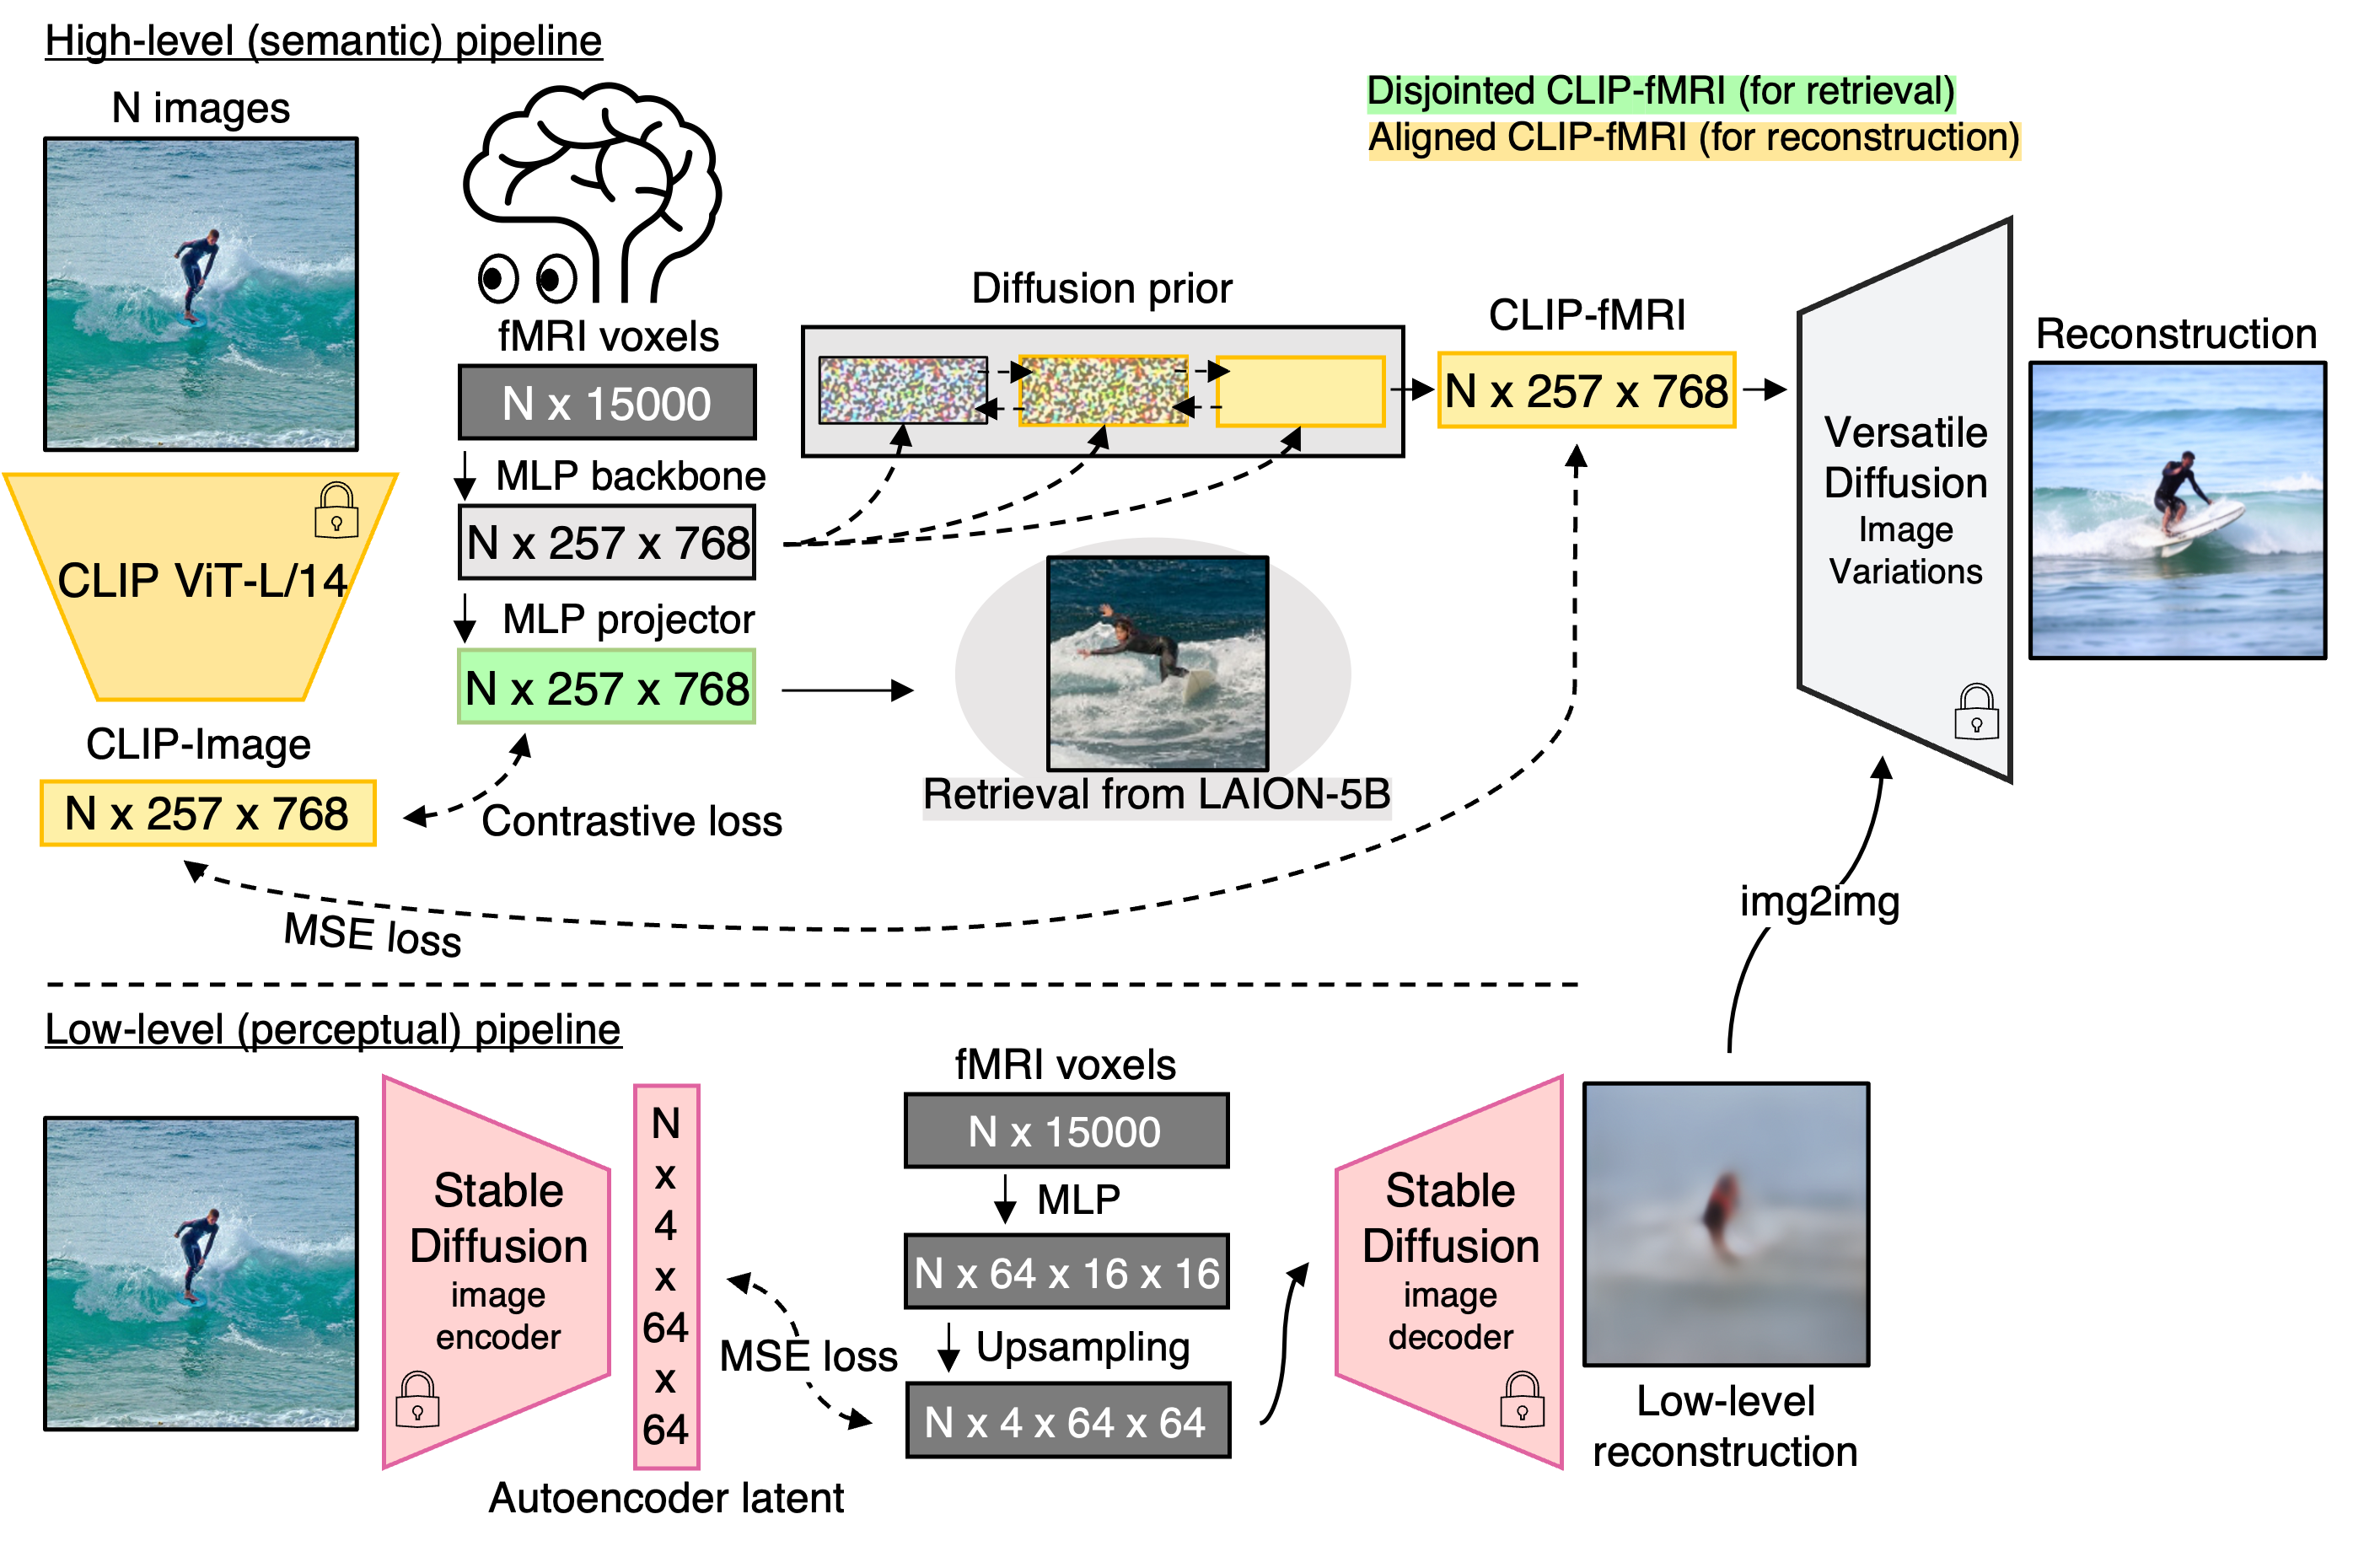

This tutorial demonstrates the application of a deep neural network modeling paradigm to the prediction of hemodynamic activity in the human visual system. Specifically, we'll use features from OpenAI's CLIP to predict voxelwise response patterns and representational geometries in a small sample of the massive 7T fMRI Natural Scenes DataSet.




Much of the code in this tutorial comes from [*DeepDive*](https://github.com/ColinConwell/DeepDive): a toolkit (and package, currently in construction) for comprehensive and highly efficient deep net feature extraction, in concert with tools for representational similarity analysis and linear probes.

Keep in mind this is an active work in progress. If you have any issues, please refer to the associated [Github](https://github.com/ColinConwell/DeepNSD) repo(s).

We welcome any and all constructive feedback.

In [2]:
# first things first, we'll clone the Github repo...
!test -d DeepDive || git clone https://github.com/ColinConwell/DeepDive
!test -d DeepNSD || git clone https://github.com/ColinConwell/DeepNSD
!test -d DeepNSD/model_opts || cp -r DeepDive/deepdive DeepNSD/model_opts #toolbox

import os
if os.path.basename(os.getcwd()) != 'DeepNSD':
    os.chdir('DeepNSD')

!uv pip install --python "/Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv/bin/python" gdown

Cloning into 'DeepDive'...
remote: Enumerating objects: 305, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 305 (delta 26), reused 40 (delta 18), pack-reused 242 (from 1)
Receiving objects: 100% (305/305), 2.52 MiB | 11.04 MiB/s, done.
Resolving deltas: 100% (166/166), done.
Cloning into 'DeepNSD'...
remote: Enumerating objects: 325, done.
remote: Counting objects: 100% (312/312), done.
remote: Compressing objects: 100% (199/199), done.
remote: Total 325 (delta 121), reused 293 (delta 106), pack-reused 13 (from 1)
Receiving objects: 100% (325/325), 120.80 MiB | 9.75 MiB/s, done.
Resolving deltas: 100% (121/121), done.
Using Python 3.12.13 environment at: /Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv
Resolved 12 packages in 690ms                                        
Prepared 2 packages in 336ms                                                 gdown                -----------------------

The brain data we'll be predicting today is the fMRI activity of 1 human subject across 16 visual cortical regions, collected in response to 1000 natural scenes from the Microsoft Coco (2017) image set.

We load and manipulate this data as a python class, with native functions built-in that allow for visualizing stimulus examples, grouping the neural responses by various kinds of metadata, and quickly constructing RDMs across arbitrary levels of organization.

In [3]:
!uv pip install --python "/Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv/bin/python" pyarrow fastparquet  #==15.0.0

   ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 2.0/2.0 MB 13.2 MB/s  0:00:00


In [3]:
import pyarrow as pa

# Clear the extension type registry BEFORE importing neural_data
try:
    import pyarrow.lib as palib
    if hasattr(palib, '_extension_type_registry'):
        registry = palib._extension_type_registry
        for key in ['pandas.period', 'pandas.interval', 'pandas.datetime']:
            registry.pop(key, None)
except:
    pass

# NOW import your modules
import pandas as pd
from neural_data import *

# This should now work
benchmark = NaturalScenesDataset()

Downloading...
From (original): https://drive.google.com/uc?id=176Vygj8SMic_p9tZtgqw60GtSA50D_VG
From (redirected): https://drive.google.com/uc?id=176Vygj8SMic_p9tZtgqw60GtSA50D_VG&confirm=t&uuid=66d068df-e238-487b-a212-f4ad2abc0ae0
To: /Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/Lab6_ImageGeneration_from_fMRI_and_BCI/DeepNSD/neural_data/natural_scenes_demo.tar.bz2
100%|██████████| 395M/395M [00:39<00:00, 9.89MB/s] 


The main data of the **benchmark()** class is organized into 3 main dataframes:
*   **benchmark.response_data** contains the average brain activity per voxel (row) per stimulus (column); the index is the *voxel_id*
*   **benchmark.metadata** contains metadata (columns) about each voxel (row), for example its ROI; the index is the *voxel_id*
*   **benchmark.stimulus_data** contains information (columns) about each stimulus (row), including its relative path



In [4]:
# here, we see the shapes of these 3 main dataframes
# there are 8461 voxels in our dataset
# ...responding to 1000 images.
print(benchmark.response_data.shape,
      benchmark.metadata.shape,
      benchmark.stimulus_data.shape)

(8461, 1000) (8461, 6) (1000, 8)


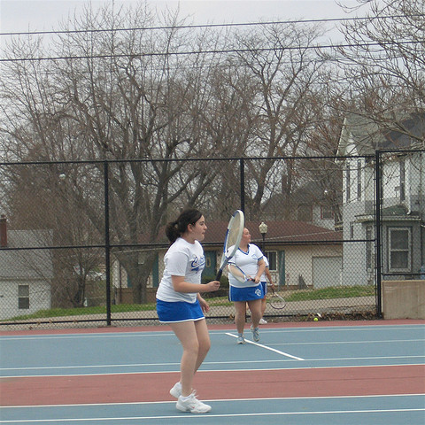

In [5]:
# here's a sample stimulus (stimulus 0)
benchmark.view_sample_stimulus(226)

Constructing target RDMs in this case requires simply specifying a set of grouping_variables (*group_vars*) -- whatever is available in the benchmark metadata. In this case, we'll create one RDM per ROI per subject.

In [6]:
# here are the various grouping_variables we could use from the metadata
print(benchmark.metadata.columns.to_list())

['subj_id', 'roi_name', 'roi_voxel_idx', 'voxel_reliability', 'roi_group', 'roi_level']


In [7]:
# while the neural_data loads with a default set of RDMs,
# here we'll overwrite these with our own
benchmark.rdms = benchmark.get_rdms(group_vars = ['roi_name', 'subj_id'])

# note, we also want to save the indices associated with the responses
# that constitute each RDM, so we can parse the predicted responses
# in our neural encoding procedure (for voxel-encoding RSA)
benchmark.rdm_indices = benchmark.get_rdm_indices(['roi_name','subj_id'])

In [8]:
!uv pip install --python "/Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv/bin/python" torchvision

Using Python 3.12.13 environment at: /Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv
Checked 1 package in 3ms


Having instantiated our neural data, we'll now 'instrumentalize' a deep neural network model to predict this data. In this example, we'll use a CLIP model, but there are a wide number of other options available in this repo.

In [9]:
# functions for loading models
sys.path.append('model_opts')
from model_options import *

In [10]:
# here's a sample of the models we've preprocessed for easy use.
list(get_model_options(model_source = 'timm').keys())[::21]

['botnet26t_256_classification',
 'dla169_classification',
 'hrnet_w64_classification',
 'pit_b_224_classification',
 'seresnet50_classification',
 'visformer_small_classification',
 'cait_xxs24_224_random',
 'eca_nfnet_l1_random',
 'jx_nest_small_random',
 'pit_ti_224_random',
 'skresnet18_random',
 'vit_small_patch16_224_random',
 'resnetv2_101x3_bitm_big_transfer',
 'ssl_resnet50_semi-supervised',
 'tf_efficientnet_b7_ap_adversarial']

In [11]:
# to use the clip model, we need OpenAI's CLIP.
# NOTE: this venv also has the unrelated `clip-py` package registered under
# the same `clip` import name (see Lab_6_CLIPDiffusion_without_fMRI.ipynb).
# We reuse the local CLIP clone from that notebook and put it first on
# sys.path so `import clip` (triggered lazily inside model_options.py)
# resolves to the real OpenAI CLIP instead.
import sys

!test -d ../CLIP || git clone https://github.com/openai/CLIP ../CLIP
!uv pip install --python "/Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv/bin/python" ftfy regex

sys.path.insert(0, '../CLIP')

Using Python 3.12.13 environment at: /Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv
Resolved 3 packages in 147ms                                         
Installed 2 packages in 2ms                                 
 + ftfy==6.3.1
 + regex==2026.11.19


This pipeline requires a few things for the models we want to test. It requires some **metadata** (the name of the model, what it's been trained on, what class of model it is); a **call** for loading the model; and (perhaps most importantly of all) the appropriate **image transforms** that'll convert our stimulus images into the right format (and distribution) for our model.

So long as you have a PyTorch model, a torchvision *transforms.Compose()* function, and a *model_string*, *model_name*, and *train_type*, you can use any model at your disposal, simply modifying the pipeline below without the *get_model_options()* function.

In [12]:
model_string = 'ViT-B/32_clip'
model_option = get_model_options()[model_string]
model_name = model_option['model_name']
train_type = model_option['train_type']

image_transforms = get_recommended_transforms(model_string)
model = eval(model_option['call'])
model = model.eval()
if torch.cuda.is_available():
  model = model.cuda()

100%|███████████████████████████████████████| 338M/338M [00:34<00:00, 10.3MiB/s]
/Users/dominik/Desktop/AGH_STUDIES/ml-for-neuroimaging-and-neuroscience/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


With our neural data instantiated, and model instrumentalized, we now begin the process of feature extraction. To do this, we first select our target layers (though in reality, you'll usually want to test all layers). We then hook the features from these target layers as we pass batches of images through the model.  Then (for computational tractability), we reduce the dimensionality of these features (using in this case a technique called sparse random projectiion).

In [13]:
# tools for feature extraction
sys.path.append('model_opts')
from feature_extraction import *

In [14]:
stimulus_loader = DataLoader(StimulusSet(benchmark.stimulus_data.image_path, image_transforms), batch_size = 64)
# this function creates a dataloader using the stimulus_data dataframe of our neural benchmark,
# and the image_transforms we loaded when we instrumentalized our model.

In [15]:
# to get the names of the model layers we'll subselect from, we'll use a convenience function
# because we're testing a vision transformer, we'll then extract every other linear layer.
model_layers = get_empty_feature_maps(model, stimulus_loader, names_only = True)
target_layers = [layer for layer in model_layers if 'Linear' in layer
                 and int(layer.split('-')[1]) % 2 == 1]

In [16]:
# once we've selected our target layers, we pass these, our model, and our dataloader through a convenience function:
feature_maps = get_all_feature_maps(model, stimulus_loader, layers_to_retain = target_layers)

Feature Extraction (Batch):   0%|          | 0/16 [00:00<?, ?it/s]

In [17]:
# here are the dimensionalities of our extracted features
# obviously, these take up a lot of RAM!
for feature_map in feature_maps:
  print(feature_map, feature_maps[feature_map].shape)

Linear-1 (1000, 153600)
Linear-3 (1000, 153600)
Linear-5 (1000, 153600)
Linear-7 (1000, 153600)
Linear-9 (1000, 153600)
Linear-11 (1000, 153600)
Linear-13 (1000, 153600)
Linear-15 (1000, 153600)
Linear-17 (1000, 153600)
Linear-19 (1000, 153600)
Linear-21 (1000, 153600)
Linear-23 (1000, 153600)


In [19]:
# tools for dimensionality reduction
sys.path.append('model_opts')
from feature_reduction import *

In [20]:
# we'll now pass our extracted feature maps (along with a model_string to save temporary files)
# through another convenience function, with parameters for the sparse random projection.
# after reducing its dimensionality, we delete the full-sized feature_map with the keep_ argument
feature_maps_redux = srp_extraction(model_string, feature_maps = feature_maps, eps = 0.1, seed = 0,
                                    delete_original_feature_maps = True)

SRP Extraction (Layer):   0%|          | 0/12 [00:00<?, ?it/s]

In [21]:
# here are the dimensionalities of our reduced feature_maps
for feature_map in feature_maps_redux:
  print(feature_map, feature_maps_redux[feature_map].shape)

Linear-1 (1000, 5920)
Linear-3 (1000, 5920)
Linear-5 (1000, 5920)
Linear-7 (1000, 5920)
Linear-9 (1000, 5920)
Linear-11 (1000, 5920)
Linear-13 (1000, 5920)
Linear-15 (1000, 5920)
Linear-17 (1000, 5920)
Linear-19 (1000, 5920)
Linear-21 (1000, 5920)
Linear-23 (1000, 5920)


Having extracted our target features and reduced their dimensionality, we now move to the bulk of the analysis: the mapping of deep net features to the brain data. In this example, we consider two mapping metrics: classic representational similarity analysis and reweighted (voxel-wise encoding) representational similarity analysis.

The first of these methods involves calculating RDMs (built with the 1 - Pearson distance) directly from each feature space, then comparing these directly to the target RDMs with a second-order (1 - Pearson) distance metric.

The second of these methods involves first fitting an encoding model per voxel per feature space -- effectively regressing the features of a given model layer onto the activation profile of a target voxel. With these encoding models, we can generate predicted activity per voxel, and use this predicted activity to build predicted (voxel-reweighted) RDMs, which we subsequently compare with tthe second (1 - Pearson) distance metric to the relevant brain RDMs.

These two metric are comparable, but make different assumptions about the nature of the information that undergirds the similarity between brain and machine. Keep this in mind if comparing the two side by side!

In [23]:
# tools for mapping deep nets to brains
# and also for some pretty plotting
sys.path.append('model_opts')
from mapping_methods import *

from plotnine import *
from plotnine import options
options.figure_size = (10,5)

In [24]:
# here, we define some convenience functions for splitting our data into train and test sets
from sklearn.preprocessing import StandardScaler

def get_splithalf_xy(feature_map, response_data, scaling = StandardScaler()):
    data_splits = {'train': {}, 'test': {}}

    data_splits['train']['X'] = scaling.fit_transform(feature_map[::2,:])
    data_splits['test']['X'] = scaling.transform(feature_map[1::2,:])

    response_data = response_data.to_numpy()
    data_splits['train']['y'] = response_data[:,::2]
    data_splits['test']['y'] = response_data[:,1::2]

    return data_splits

def get_splithalf_rdms(rdms):
    split_rdms = {}
    for roi_name in rdms:
        split_rdms[roi_name] = {}
        for subj_id in rdms[roi_name]:
            split_rdms[roi_name][subj_id] = {'train': rdms[roi_name][subj_id][::2,::2],
                                            'test': rdms[roi_name][subj_id][1::2,1::2]}

    return split_rdms

In [27]:
# here, we begin the scoring procedure, first defining which metrics we want to save
scoresheet_lists = {metric: [] for metric in ['crsa','wrsa']}

#we now loop through all our target_layers, scoring each as we go
for model_layer_index, model_layer in enumerate(tqdm(feature_maps_redux, desc = 'Mapping (Layer)')):
    xy = get_splithalf_xy(feature_maps_redux[model_layer], benchmark.response_data)

    # these are the value of the lambda penalty in the ridge regression
    alpha_values = np.logspace(-1,5,7).tolist()

    # this is the regression that maps the feature space to the voxels.
    # it's a multioutput regression, so it fits all voxels simultaneously.
    # it automatically performs leave one out cross-validation ...
    # ... to choose the optimal lambda penalty. we save this loocv score
    # ... as the predictive score for the training set, but also ...
    # ... evaluate the optimal lambda regression on a heldout test set.
    regression = RidgeCV(alphas=alpha_values, store_cv_results = True,
                          scoring = 'explained_variance')

    # here's where we extract the optimal lambda and generate the test predictions
    regression.fit(xy['train']['X'], xy['train']['y'].transpose())
    best_alpha_index = alpha_values.index(regression.alpha_)
    predictions = {'train': regression.cv_results_[:, :, best_alpha_index],
                   'test': xy['test']['X'].dot(regression.coef_.transpose()) + regression.intercept_}

    for metric in scoresheet_lists:

        if metric == 'crsa':
            # even though the classic rsa metric is nonparametric
            # it's still wise to split into a train / test set
            # for the purposes of selecting the maximally correspondent layers
            splithalf_rdms = get_splithalf_rdms(benchmark.rdms)
            model_rdms = {'train': 1 - np.corrcoef(feature_maps_redux[model_layer][::2,:]),
                          'test': 1 - np.corrcoef(feature_maps_redux[model_layer][1::2,:])}

            for score_set in ['train', 'test']:
                for roi_name in benchmark.rdms:
                    for subj_id in benchmark.rdms[roi_name]:
                        target_rdm = splithalf_rdms[roi_name][subj_id][score_set]
                        score = compare_rdms(model_rdms[score_set], target_rdm)
                        # what we've done in the lines above is loop through all
                        # possible [ROI][subj_id] RDMs and compared them to the layer RDM

                        # we save this score and other data in a dictionary
                        # for later aggregation in a scoresheet
                        scoresheet = {'score': score,
                                      'score_set': score_set,
                                      'roi_name': roi_name,
                                      'subj_id': subj_id,
                                      'model': model_name,
                                      'train_type': train_type,
                                      'model_layer': model_layer,
                                      'model_layer_index': model_layer_index,
                                      'distance_1': 'pearson_r',
                                      'distance_2': 'pearson_r'}

                        scoresheet_lists['crsa'].append(scoresheet)

        if metric == 'srpr':
            # we can, if we want, save the predictive scores per voxel
            # prior to aggregating the voxelwise predictions in an RDM
            for score_set in ['train','test']:
                if score_set == 'train':
                    y = xy['train']['y'].transpose()
                    y_pred = predictions['train']
                if score_set == 'test':
                    y = xy['test']['y'].transpose()
                    y_pred = predictions['test']
                score = score_func(y, y_pred)

                neuroid_ids = benchmark.response_data.index
                # notice in this dictionary that we're saving a score per voxel
                # individual units we occasionally called 'neuroids',
                # to have a general term across different brain units
                scoresheet = pd.DataFrame({'neuroid_id': neuroid_ids,
                                            'score': score,
                                            'alpha': alpha_values[best_alpha_index],
                                            'score_set': score_set,
                                            'score_type': 'pearson_r',
                                            'model': model_name,
                                            'train_type': train_type,
                                            'model_layer': model_layer,
                                            'model_layer_index': model_layer_index})


                scoresheet_lists['srpr'].append(scoresheet)

        if metric == 'wrsa':
            # now we perform the weighted rsa
            splifhalf_rdms = get_splithalf_rdms(benchmark.rdms)
            # the rdm_indices tell us which predictions
            # from the regression correspond to which voxel
            rdm_indices_dict = benchmark.rdm_indices

            for score_set in ['train', 'test']:
                for roi_name in benchmark.rdms:
                    for subj_id in benchmark.rdms[roi_name]:
                        # again we iterate through all [ROI][subj_id] combos ...
                        # aggregating the responses from the fitted regression
                        # into the relevant predicted RDMs we compare to actual RDMS
                        rdm_indices = rdm_indices_dict[roi_name][subj_id]
                        prediction_subset = predictions[score_set][:,rdm_indices]
                        model_rdm = 1 - np.corrcoef(prediction_subset)
                        target_rdm = splithalf_rdms[roi_name][subj_id][score_set]
                        score = compare_rdms(model_rdm, target_rdm)

                        # this scoresheet should be identical in its dimensionality
                        # and composition to the crsa scoresheet
                        scoresheet = {'score': score,
                                      'score_set': score_set,
                                      'alpha': alpha_values[best_alpha_index],
                                      'roi_name': roi_name,
                                      'subj_id': subj_id,
                                      'model': model_name,
                                      'train_type': train_type,
                                      'model_layer': model_layer,
                                      'model_layer_index': model_layer_index,
                                      'distance_1': 'pearson_r',
                                      'distance_2': 'pearson_r'}

                        scoresheet_lists['wrsa'].append(scoresheet)

# now, we concatenate our various results into easily accessible dataframes
# adding relevant bits of metadata for group_by operations
prime_metadata = benchmark.metadata[['roi_name','subj_id']]

results = {}

for metric in scoresheet_lists:
  if 'rsa' in metric:
      results[metric] = pd.DataFrame(scoresheet_lists[metric])
  if 'srpr' in metric:
      results[metric] = (pd.concat(scoresheet_lists[metric])
                          .merge(prime_metadata, on = benchmark.index_name))

Mapping (Layer):   0%|          | 0/12 [00:00<?, ?it/s]

After fitting our regressions and computing the relevant representational similarities, we can now visualize the scores for individual ROIs across model layer, simultaneously scrutinizing the drop in generalization from training to test set (if in fact there is one).

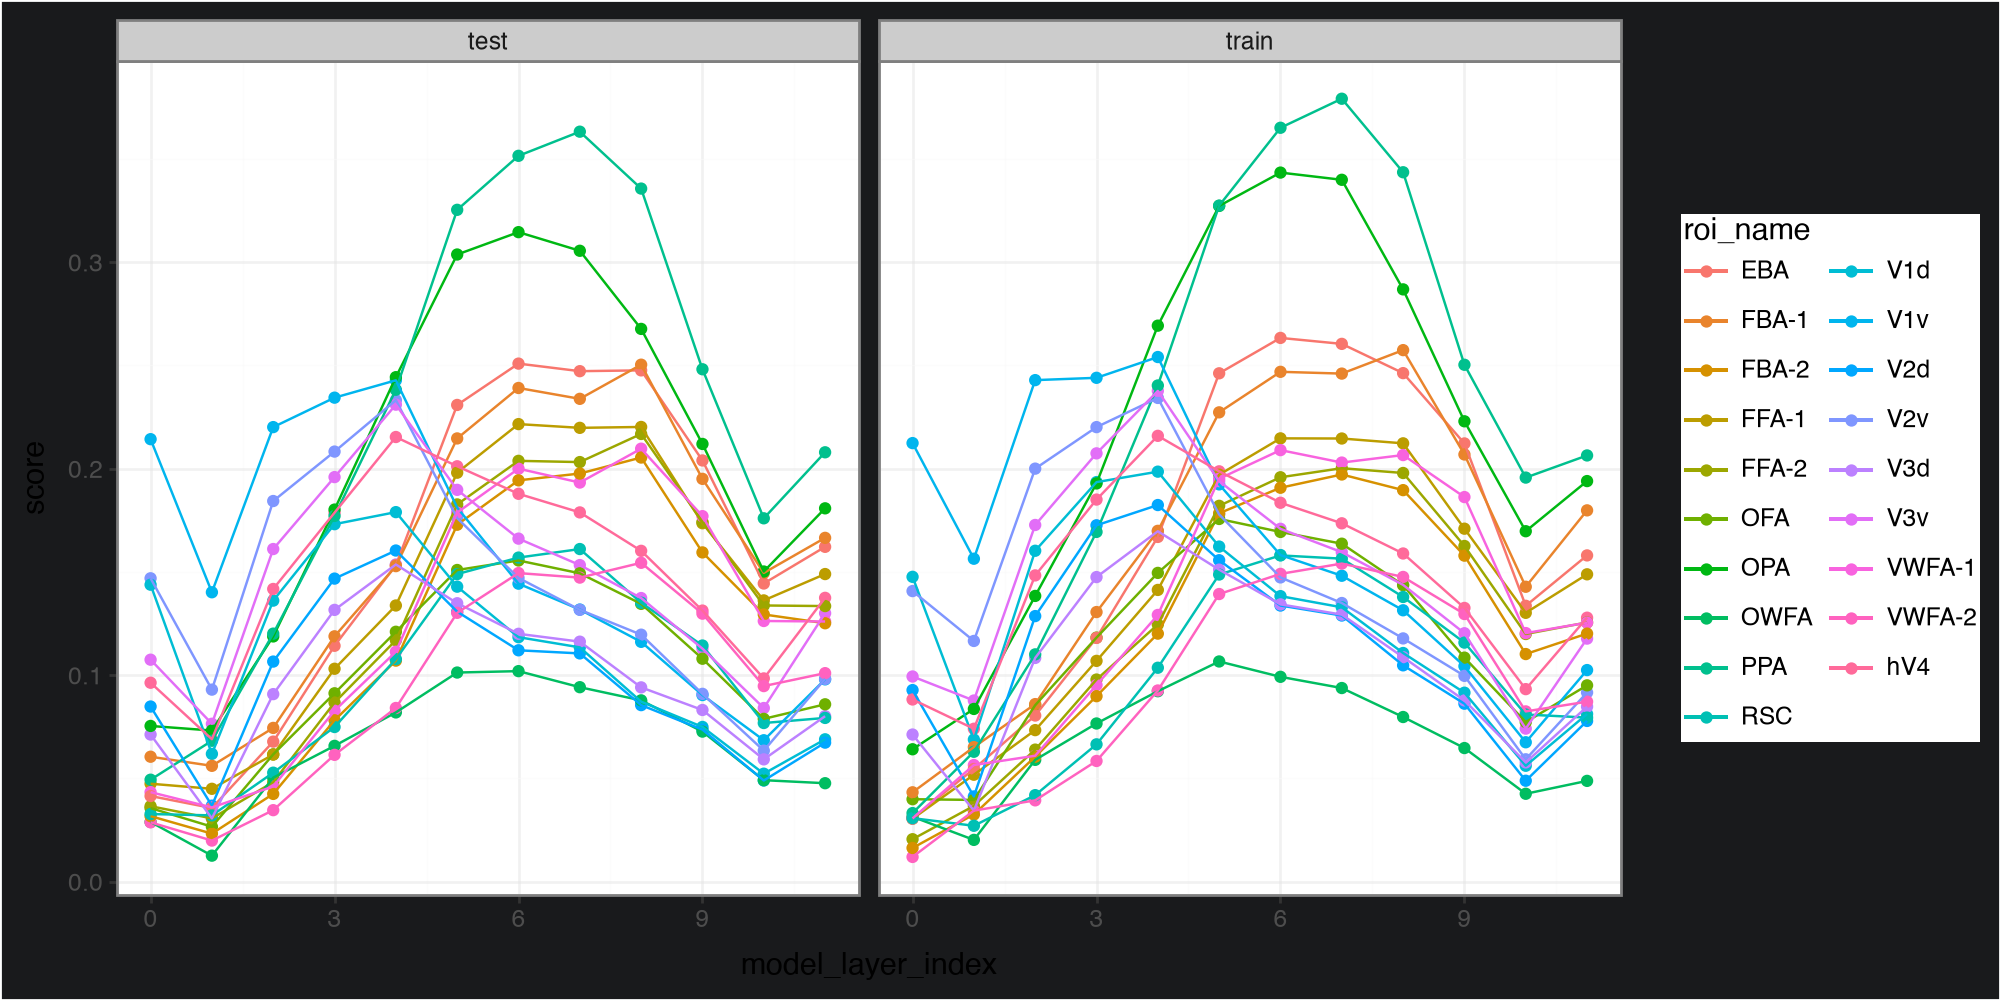

In [28]:
(ggplot(results['crsa'], aes('model_layer_index', 'score', color = 'roi_name', group = 'roi_name')) +
 geom_point() + geom_line() + facet_wrap('~score_set') + theme_bw())

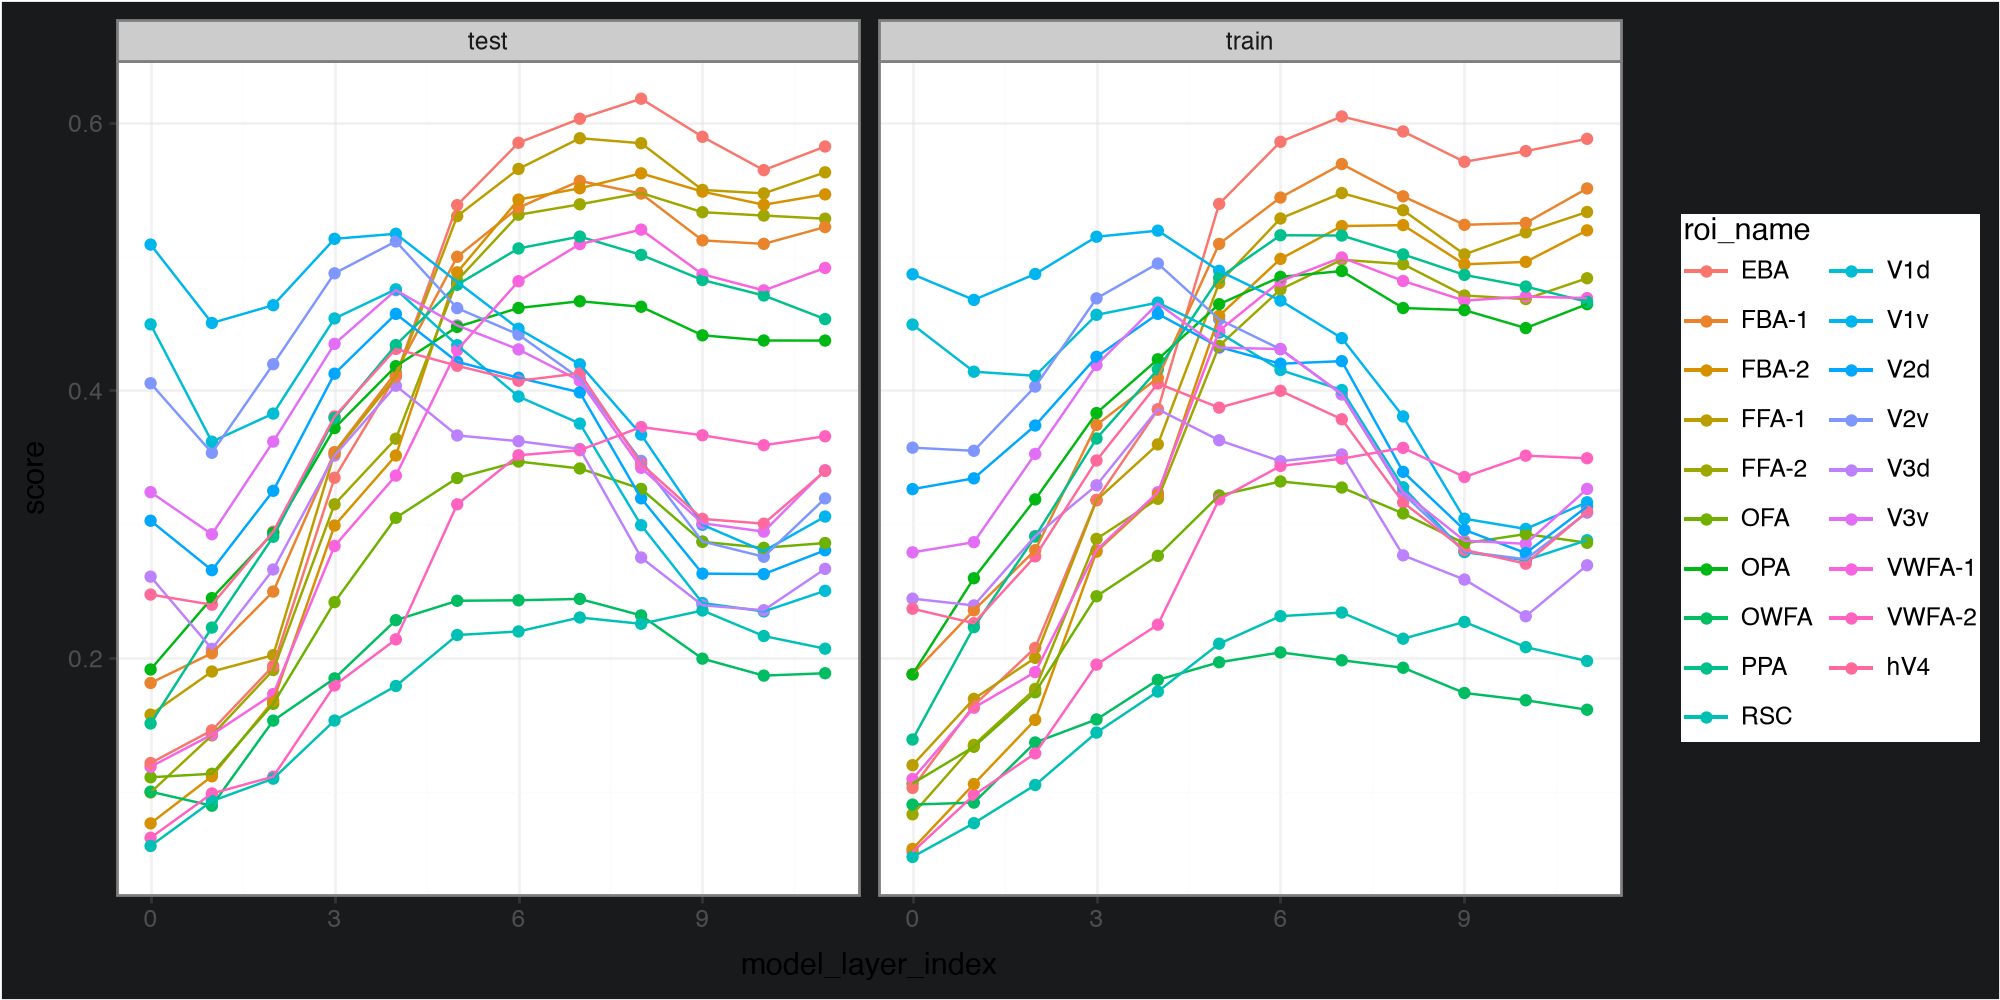

In [29]:
(ggplot(results['wrsa'], aes('model_layer_index', 'score', color = 'roi_name', group = 'roi_name')) +
 geom_point() + geom_line() + facet_wrap('~score_set') + theme_bw())

And there we have it! You've just benchmarked a CLIP model on the NSD data.

Here is a retrieval of the closeset stimoli given fMRI.

Optional:
If you have time change it from retrieval to full generation

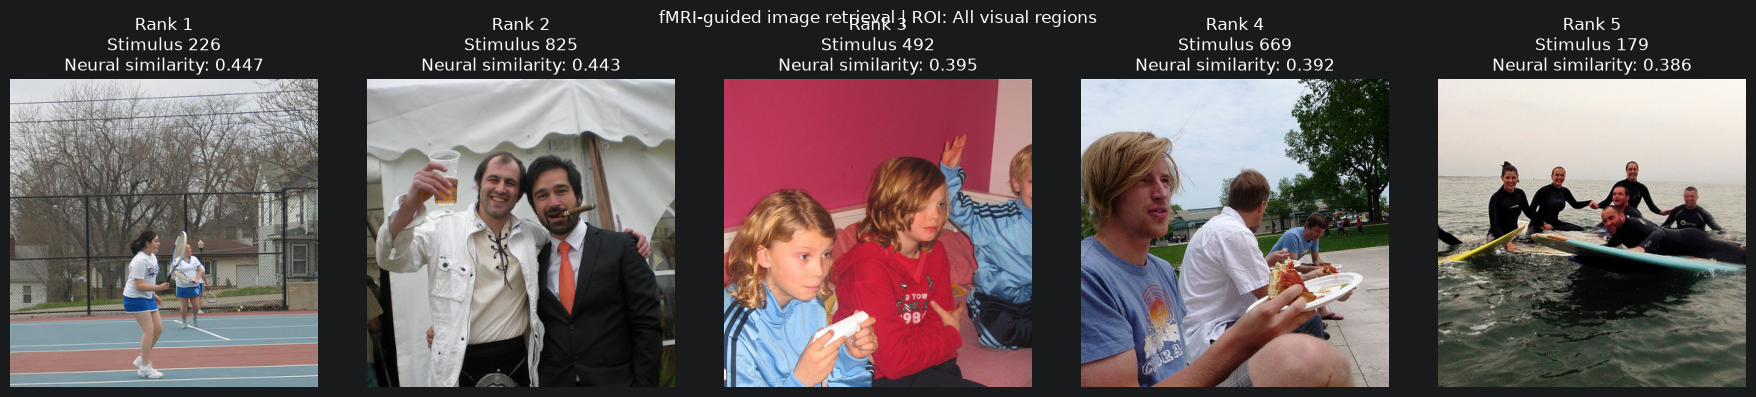

Query stimulus: 0
Number of voxels: 8461

Retrieved stimuli:
Stimulus 226: similarity = 0.4471
Stimulus 825: similarity = 0.4425
Stimulus 492: similarity = 0.3947
Stimulus 669: similarity = 0.3923
Stimulus 179: similarity = 0.3863


In [30]:

# ============================================================
# fMRI-guided image retrieval from the Natural Scenes Dataset
# Uses the existing benchmark object and its 16 visual ROIs.
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# ------------------------------------------------------------
# 1. Select the fMRI observation to decode
# ------------------------------------------------------------

# Select an observation (0-999)
query_idx = 0

# None = use all available visual regions
# Alternatively, specify an ROI name, e.g. 'V1'
selected_roi = None

response_df = benchmark.response_data
metadata = benchmark.metadata

# Preserve the original voxel ordering
if selected_roi is None:
    voxel_ids = response_df.index
else:
    voxel_ids = metadata.index[
        metadata['roi_name'] == selected_roi
    ].intersection(response_df.index)

if len(voxel_ids) == 0:
    raise ValueError("No voxels found for the selected ROI.")

# Matrix: stimuli x voxels
fmri_matrix = response_df.loc[voxel_ids].to_numpy(
    dtype=np.float32
).T

# Query brain response
query_fmri = fmri_matrix[query_idx]

# ------------------------------------------------------------
# 2. Compare the query with the other fMRI responses
# ------------------------------------------------------------

# Center each response across voxels
query_centered = query_fmri - query_fmri.mean()

candidate_centered = (
    fmri_matrix - fmri_matrix.mean(axis=1, keepdims=True)
)

# Normalize
query_norm = np.linalg.norm(query_centered)

candidate_norms = np.linalg.norm(
    candidate_centered, axis=1
)

if query_norm == 0:
    raise ValueError("Query fMRI response has zero variance.")

# Pearson correlation across voxels
similarities = (
    candidate_centered @ query_centered
) / (candidate_norms * query_norm + 1e-8)

# Exclude the original stimulus
similarities[query_idx] = -np.inf

# Retrieve the five closest neural patterns
top_k = 5
top_indices = np.argsort(similarities)[::-1][:top_k]

# ------------------------------------------------------------
# 3. Display the corresponding images
# ------------------------------------------------------------

fig, axes = plt.subplots(1, top_k, figsize=(18, 4))

for rank, (idx, ax) in enumerate(zip(top_indices, axes)):

    image_path = benchmark.stimulus_data.iloc[idx]['image_path']

    if not os.path.isfile(image_path):
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.axis("off")

    ax.set_title(
        f"Rank {rank + 1}\n"
        f"Stimulus {idx}\n"
        f"Neural similarity: {similarities[idx]:.3f}"
    )

plt.suptitle(
    f"fMRI-guided image retrieval | "
    f"ROI: {selected_roi or 'All visual regions'}"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Report results
# ------------------------------------------------------------

print("Query stimulus:", query_idx)
print("Number of voxels:", len(voxel_ids))
print("\nRetrieved stimuli:")

for idx in top_indices:
    print(
        f"Stimulus {idx}: "
        f"similarity = {similarities[idx]:.4f}"
    )


### From retrieval to generation (optional extension)

Instead of just retrieving the closest *stored* image by correlating raw fMRI patterns, we can decode a CLIP image embedding directly from the fMRI response and use it to drive the same CLIP-guided diffusion model from `Lab_6_CLIPDiffusion_without_fMRI.ipynb` - generating a brand new image conditioned on brain activity instead of on a text prompt.

The diffusion sampling step below is the expensive part (same 512x512, 1000-step model as the other notebook) and is disabled by default (`RUN_GENERATION = False`). Flip it to `True` on a machine with a CUDA GPU - it will not finish in reasonable time on a CPU-only machine.

In [31]:
# ============================================================
# Step 1: decode a CLIP image embedding directly from the fMRI pattern
# ============================================================

import numpy as np
import torch
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

import clip as openai_clip  # the real OpenAI CLIP (sys.path fixed above)

clip_device = 'cuda' if torch.cuda.is_available() else 'cpu'
clip_model_b16, clip_preprocess_b16 = openai_clip.load('ViT-B/16', device=clip_device)
clip_model_b16.eval()

# ------------------------------------------------------------
# 1a. Embed every NSD stimulus with CLIP (ViT-B/16, matching the model
#     used for CLIP-guided diffusion in the companion notebook)
# ------------------------------------------------------------

stimulus_paths = benchmark.stimulus_data['image_path'].tolist()

clip_embeds = []
with torch.no_grad():
    for i in range(0, len(stimulus_paths), 64):
        batch_paths = stimulus_paths[i:i + 64]
        batch = torch.stack([
            clip_preprocess_b16(Image.open(p).convert('RGB'))
            for p in batch_paths
        ]).to(clip_device)
        clip_embeds.append(clip_model_b16.encode_image(batch).float().cpu())

clip_embeds = torch.cat(clip_embeds).numpy()  # [n_stimuli, 512]

# ------------------------------------------------------------
# 1b. Fit a voxel -> CLIP-embedding decoder, holding out the query
#     stimulus so the "generation" is from genuinely unseen brain data
# ------------------------------------------------------------

fmri_all = benchmark.response_data.to_numpy(dtype=np.float32).T  # [n_stimuli, n_voxels]

train_mask = np.ones(len(fmri_all), dtype=bool)
train_mask[query_idx] = False

scaler = StandardScaler()
X_train = scaler.fit_transform(fmri_all[train_mask])
X_query = scaler.transform(fmri_all[query_idx:query_idx + 1])

alpha_values = np.logspace(-1, 5, 7).tolist()
decoder = RidgeCV(alphas=alpha_values, scoring='explained_variance')
decoder.fit(X_train, clip_embeds[train_mask])

predicted_embed = torch.tensor(decoder.predict(X_query)[0], dtype=torch.float32)
predicted_embed = predicted_embed / predicted_embed.norm()

# Sanity check: how close is the decoded embedding to the *real* CLIP
# embedding of the stimulus the subject actually saw?
true_embed = torch.tensor(clip_embeds[query_idx])
true_embed = true_embed / true_embed.norm()
cos_sim = (predicted_embed @ true_embed).item()
print(f'Decoded vs. true CLIP-embedding cosine similarity: {cos_sim:.3f}')

Decoded vs. true CLIP-embedding cosine similarity: 0.757


In [32]:
# ============================================================
# Step 2: drive CLIP-guided diffusion with the decoded brain embedding
# ============================================================
#
# Reuses the exact same 512x512 class-conditional diffusion model and
# CLIP-guidance loop as Lab_6_CLIPDiffusion_without_fMRI.ipynb, except the
# guidance target is the fMRI-decoded CLIP embedding from the previous
# cell instead of a text embedding - i.e. "imagine the image that
# produced this brain activity" rather than "imagine the image that
# matches this caption".

RUN_GENERATION = False  # set True on a machine with a CUDA GPU

if RUN_GENERATION:
    import sys
    from torch import nn
    from torch.nn import functional as F
    from torchvision import transforms
    from torchvision.transforms import functional as TF
    from tqdm.notebook import tqdm
    from IPython import display as ipydisplay

    sys.path.insert(0, '../guided-diffusion')
    from guided_diffusion.script_util import create_model_and_diffusion, model_and_diffusion_defaults

    gen_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

    model_config = model_and_diffusion_defaults()
    model_config.update({
        'attention_resolutions': '32, 16, 8',
        'class_cond': True,
        'diffusion_steps': 1000,
        'rescale_timesteps': True,
        'timestep_respacing': '1000',
        'image_size': 512,
        'learn_sigma': True,
        'noise_schedule': 'linear',
        'num_channels': 256,
        'num_head_channels': 64,
        'num_res_blocks': 2,
        'resblock_updown': True,
        'use_fp16': True,
        'use_scale_shift_norm': True,
    })

    diff_model, diffusion = create_model_and_diffusion(**model_config)
    diff_model.load_state_dict(torch.load('../512x512_diffusion.pt', map_location='cpu'))
    diff_model.requires_grad_(False).eval().to(gen_device)
    for name, param in diff_model.named_parameters():
        if 'qkv' in name or 'norm' in name or 'proj' in name:
            param.requires_grad_()
    if model_config['use_fp16']:
        diff_model.convert_to_fp16()

    clip_size = clip_model_b16.visual.input_resolution
    clip_normalize = transforms.Normalize(mean=[0.48145466, 0.4578275, 0.40821073],
                                           std=[0.26862954, 0.26130258, 0.27577711])

    class MakeCutouts(nn.Module):
        def __init__(self, cut_size, cutn, cut_pow=1.):
            super().__init__()
            self.cut_size = cut_size
            self.cutn = cutn
            self.cut_pow = cut_pow

        def forward(self, input):
            sideY, sideX = input.shape[2:4]
            max_size = min(sideX, sideY)
            min_size = min(sideX, sideY, self.cut_size)
            cutouts = []
            for _ in range(self.cutn):
                size = int(torch.rand([]) ** self.cut_pow * (max_size - min_size) + min_size)
                offsetx = torch.randint(0, sideX - size + 1, ())
                offsety = torch.randint(0, sideY - size + 1, ())
                cutout = input[:, :, offsety:offsety + size, offsetx:offsetx + size]
                cutouts.append(F.adaptive_avg_pool2d(cutout, self.cut_size))
            return torch.cat(cutouts)

    def spherical_dist_loss(x, y):
        x = F.normalize(x, dim=-1)
        y = F.normalize(y, dim=-1)
        return (x - y).norm(dim=-1).div(2).arcsin().pow(2).mul(2)

    def tv_loss(input):
        input = F.pad(input, (0, 1, 0, 1), 'replicate')
        x_diff = input[..., :-1, 1:] - input[..., :-1, :-1]
        y_diff = input[..., 1:, :-1] - input[..., :-1, :-1]
        return (x_diff ** 2 + y_diff ** 2).mean([1, 2, 3])

    batch_size = 1
    clip_guidance_scale = 1000  # how much the image should look like the decoded embedding
    tv_scale = 150              # smoothness of the final output
    cutn = 40
    cut_pow = 0.5
    skip_timesteps = 0
    seed = 0

    target_embed = predicted_embed.to(gen_device).float()
    make_cutouts = MakeCutouts(clip_size, cutn, cut_pow)
    cur_t = None

    def cond_fn(x, t, y=None):
        with torch.enable_grad():
            x = x.detach().requires_grad_()
            n = x.shape[0]
            my_t = torch.ones([n], device=gen_device, dtype=torch.long) * cur_t
            out = diffusion.p_mean_variance(diff_model, x, my_t, clip_denoised=False, model_kwargs={'y': y})
            fac = diffusion.sqrt_one_minus_alphas_cumprod[cur_t]
            x_in = out['pred_xstart'] * fac + x * (1 - fac)
            clip_in = clip_normalize(make_cutouts(x_in.add(1).div(2)))
            image_embeds = clip_model_b16.encode_image(clip_in).float().view([cutn, n, -1])
            dists = spherical_dist_loss(image_embeds, target_embed.unsqueeze(0))
            losses = dists.mean(0)
            tv_losses = tv_loss(x_in)
            loss = losses.sum() * clip_guidance_scale + tv_losses.sum() * tv_scale
            return -torch.autograd.grad(loss, x)[0]

    torch.manual_seed(seed)
    sample_fn = diffusion.p_sample_loop_progressive
    cur_t = diffusion.num_timesteps - skip_timesteps - 1

    samples = sample_fn(
        diff_model,
        (batch_size, 3, model_config['image_size'], model_config['image_size']),
        clip_denoised=False,
        model_kwargs={'y': torch.zeros([batch_size], device=gen_device, dtype=torch.long)},
        cond_fn=cond_fn,
        progress=True,
        skip_timesteps=skip_timesteps,
        randomize_class=True,
    )

    for j, sample in enumerate(samples):
        cur_t -= 1
        if j % 100 == 0 or cur_t == -1:
            for k, image in enumerate(sample['pred_xstart']):
                filename = f'brain_decoded_{query_idx:05}.png'
                TF.to_pil_image(image.add(1).div(2).clamp(0, 1)).save(filename)
                ipydisplay.display(ipydisplay.Image(filename))
else:
    print('RUN_GENERATION is False - skipping the diffusion sampling loop '
          '(set to True on a GPU machine to actually render the image).')

RUN_GENERATION is False - skipping the diffusion sampling loop (set to True on a GPU machine to actually render the image).
